# 09f topic clusters and two model scores

**Question:** Do the distributions of `p_support` and `p_skeptic` differ across topic clusters?

The input is `09f_interpretable_assignments_with_two_scores.parquet`, joined by `comment_id`. Each row is one comment. `primary_cluster` and `topic_name_en` come from 09f; the two `p_` columns are scores generated by a separate model. This analysis concerns associations between topics and **model scores**, not verified human stances. The two scores are not mutually exclusive categories.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import chi2_contingency
from sklearn.model_selection import GroupShuffleSplit

DATA_PATH = Path(r"E:\Dataminingproject\Data\09f_interpretable_assignments_with_two_scores.parquet")
SEED = 42
TOP_QUANTILE = 0.90  # Same top-decile cutoff rule as the word-association notebook.

if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Input file not found: {DATA_PATH}")
print("Input: ", DATA_PATH)


Input:  E:\Dataminingproject\Data\09f_interpretable_assignments_with_two_scores.parquet


## 1. Load and check the data

Read only the columns needed here. `post_id` groups comments when splitting training and held-out posts, so comments from the same post cannot appear in both groups.


In [2]:
columns = [
    "comment_id", "post_id", "subreddit", "primary_cluster", "topic_name_en",
    "p_support", "p_skeptic",
]
df = pd.read_parquet(DATA_PATH, columns=columns)

assert df["comment_id"].notna().all() and df["comment_id"].is_unique
assert df[["post_id", "primary_cluster", "topic_name_en", "p_support", "p_skeptic"]].notna().all().all()
assert df[["p_support", "p_skeptic"]].ge(0).all().all()
assert df[["p_support", "p_skeptic"]].le(1).all().all()
assert df.groupby("primary_cluster")["topic_name_en"].nunique().eq(1).all()

print(f"Comments: {len(df):,};clusters: {df['primary_cluster'].nunique()};subreddits: {df['subreddit'].nunique()}")
display(df.groupby(["primary_cluster", "topic_name_en"]).size().rename("Comments").reset_index())


Comments: 28,230;clusters: 9;subreddits: 6


,primary_cluster,topic_name_en,Comments
0,0,"Future climate risk, adaptation, and human con...",3426
1,1,"Nuclear energy, fusion, and low-carbon power",1360
2,2,"Climate belief, denial, and public communication",4401
3,3,Electric vehicles and clean transport,1824
4,4,"Climate observations, weather change, and phys...",3583
5,5,"Emission responsibility, consumption, and glob...",3760
6,6,"Renewables, grids, and storage",4027
7,7,Fossil fuels and transition political economy,3561
8,8,"Greenhouse gases, carbon cycle, and carbon rem...",2288


## 2. Reuse the ARM definition of a high score

Use the same random seed and `GroupShuffleSplit` as the word-association notebook. Calculate each score's 90th percentile in the training portion only, then apply those fixed cutoffs to all 09f comments. `support_top10` and `skeptic_top10` are **high model-score groups**, not human stance labels. Their shares in the full sample need not equal exactly 10%.


In [3]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_index, test_index = next(splitter.split(df, groups=df["post_id"]))
assert set(df.iloc[train_index]["post_id"]).isdisjoint(set(df.iloc[test_index]["post_id"]))

thresholds = {
    "support": df.iloc[train_index]["p_support"].quantile(TOP_QUANTILE),
    "skeptic": df.iloc[train_index]["p_skeptic"].quantile(TOP_QUANTILE),
}
for dimension in thresholds:
    df[f"{dimension}_top10"] = df[f"p_{dimension}"].ge(thresholds[dimension])

overall = df[["support_top10", "skeptic_top10"]].mean()
print(f"High-support cutoff: {thresholds['support']:.4f};full-sample high-score share: {overall['support_top10']:.1%}")
print(f"High-skepticism cutoff: {thresholds['skeptic']:.4f};full-sample high-score share: {overall['skeptic_top10']:.1%}")
print("Comments high on both scores: ", int((df["support_top10"] & df["skeptic_top10"]).sum()))


High-support cutoff: 0.9864;full-sample high-score share: 10.0%
High-skepticism cutoff: 0.8070;full-sample high-score share: 10.4%
Comments high on both scores:  49


## 3. Compare the nine topics

The *high-score share* is the proportion of comments within a topic above the relevant model-score cutoff. The *relative-to-all ratio* is that topic's share divided by the full-sample share; a ratio above 1 indicates that a high model score is more common in that topic. Mean scores are descriptive and must not be read as proportions of actual supporters or skeptics.


In [4]:
summary = (
    df.groupby(["primary_cluster", "topic_name_en"], as_index=False)
      .agg(
          comments=("comment_id", "size"),
          mean_support=("p_support", "mean"),
          mean_skeptic=("p_skeptic", "mean"),
          support_high_count=("support_top10", "sum"),
          skeptic_high_count=("skeptic_top10", "sum"),
          support_high_share=("support_top10", "mean"),
          skeptic_high_share=("skeptic_top10", "mean"),
      )
      .sort_values("primary_cluster")
)
for dimension in ("support", "skeptic"):
    summary[f"{dimension}_relative_to_all"] = (
        summary[f"{dimension}_high_share"] / overall[f"{dimension}_top10"]
    )
assert summary["comments"].sum() == len(df)

shown = summary.rename(columns={
    "primary_cluster": "Cluster", "topic_name_en": "Topic", "comments": "Comments",
    "mean_support": "Mean support score", "mean_skeptic": "Mean skepticism score",
    "support_high_count": "High-support count", "skeptic_high_count": "High-skepticism count",
    "support_high_share": "High-support share", "skeptic_high_share": "High-skepticism share",
    "support_relative_to_all": "Support relative to all",
    "skeptic_relative_to_all": "Skepticism relative to all",
}).copy()
for col in ("High-support share", "High-skepticism share"):
    shown[col] = shown[col].map(lambda value: f"{value:.1%}")
display(shown.round(2))


,Cluster,Topic,Comments,Mean support score,Mean skepticism score,High-support count,High-skepticism count,High-support share,High-skepticism share,Support relative to all,Skepticism relative to all
0,0,"Future climate risk, adaptation, and human con...",3426,0.44,0.18,551,458,16.1%,13.4%,1.61,1.29
1,1,"Nuclear energy, fusion, and low-carbon power",1360,0.20,0.03,51,14,3.8%,1.0%,0.38,0.10
2,2,"Climate belief, denial, and public communication",4401,0.38,0.33,538,1139,12.2%,25.9%,1.22,2.50
3,3,Electric vehicles and clean transport,1824,0.20,0.02,45,23,2.5%,1.3%,0.25,0.12
4,4,"Climate observations, weather change, and phys...",3583,0.11,0.20,67,556,1.9%,15.5%,0.19,1.50
5,5,"Emission responsibility, consumption, and glob...",3760,0.53,0.11,706,235,18.8%,6.2%,1.88,0.60
6,6,"Renewables, grids, and storage",4027,0.47,0.04,417,77,10.4%,1.9%,1.04,0.18
7,7,Fossil fuels and transition political economy,3561,0.36,0.08,266,130,7.5%,3.7%,0.75,0.35
8,8,"Greenhouse gases, carbon cycle, and carbon rem...",2288,0.31,0.17,181,291,7.9%,12.7%,0.79,1.23


## 4. Plot the high-score share in each topic

The dashed line shows the high-score share across all 09f comments. C0–C8 correspond to the cluster IDs in the table above.


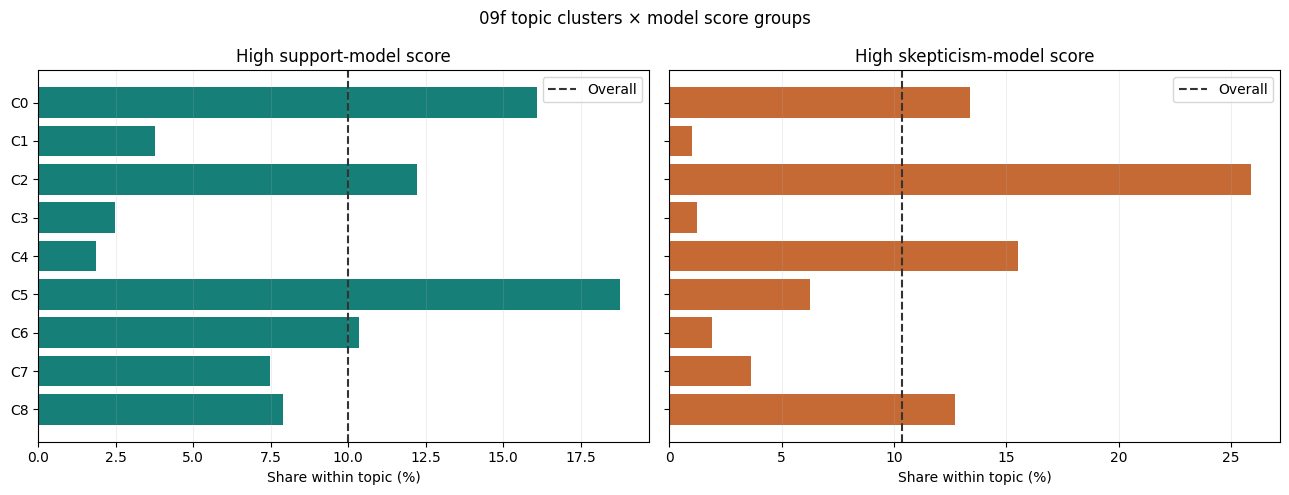

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, dimension, title, color in [
    (axes[0], "support", "High support-model score", "#167f77"),
    (axes[1], "skeptic", "High skepticism-model score", "#c66a35"),
]:
    values = summary[f"{dimension}_high_share"] * 100
    ax.barh([f"C{i}" for i in summary["primary_cluster"]], values, color=color)
    ax.axvline(overall[f"{dimension}_top10"] * 100, color="#333333", linestyle="--", label="Overall")
    ax.set_xlabel("Share within topic (%)")
    ax.set_title(title)
    ax.grid(axis="x", alpha=0.2)
    ax.legend()
axes[0].invert_yaxis()
fig.suptitle("09f topic clusters × model score groups")
fig.tight_layout()
plt.show()


## 5. Measure association and interpret it

The chi-square test checks whether the high-score shares are equal across the nine topics. Cramér's V describes association strength. With a large sample, a small p-value alone says little about practical importance. Association does not show that a topic **causes** a stance.


In [7]:
for dimension in ("support", "skeptic"):
    counts = pd.crosstab(df["primary_cluster"], df[f"{dimension}_top10"])
    chi2, p_value, _, _ = chi2_contingency(counts)
    cramers_v = np.sqrt(chi2 / (len(df) * min(counts.shape[0] - 1, counts.shape[1] - 1)))
    highest = summary.loc[summary[f"{dimension}_high_share"].idxmax()]
    print(
        f"{dimension}: Cramér's V={cramers_v:.3f}, p={p_value:.3g}; "
        f"highest in C{int(highest['primary_cluster'])} "
        f"({highest[f'{dimension}_high_share']:.1%}, "
        f"{highest[f'{dimension}_relative_to_all']:.2f}× the full-sample share)"
    )

print("\nInterpretation: topic clusters are associated with model scores, but topic words may themselves influence scores derived from the same comments.")
print("These results do not estimate the actual share of supporters or skeptics in each topic.")
print("To study actual stances, sample original comments across topics and score groups for blind human review.")


support: Cramér's V=0.185, p=3.32e-202; highest in C5 (18.8%, 1.88× the full-sample share)
skeptic: Cramér's V=0.275, p=0; highest in C2 (25.9%, 2.50× the full-sample share)

Interpretation: topic clusters are associated with model scores, but topic words may themselves influence scores derived from the same comments.
These results do not estimate the actual share of supporters or skeptics in each topic.
To study actual stances, sample original comments across topics and score groups for blind human review.
